In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['target'] = iris.target

# Display dataset
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


Select input and output features

In [3]:
# Select only two classes
df = df[df['target'] != 2]

# Input features
X = df.iloc[:, :4]

# Target variable
y = df['target']

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


Split dataset

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 80
Testing samples: 20


Feature scaling

In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

Create and train the Single Layer Perceptron

In [6]:
# Create perceptron model
model = Perceptron(
    max_iter=1000,
    eta0=0.1,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

print("Single Layer Perceptron Training Completed!")

Single Layer Perceptron Training Completed!


Make predictions

In [7]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
[1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0]

Predicted Values:
[1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0]


Calculate accuracy

In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


Confusion matrix

Confusion Matrix:
[[12  0]
 [ 0  8]]


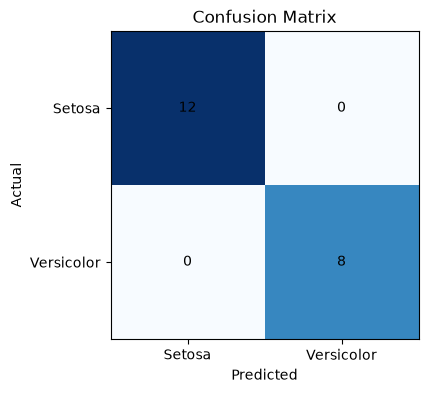

In [9]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))

plt.imshow(cm, cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ['Setosa', 'Versicolor'])
plt.yticks([0, 1], ['Setosa', 'Versicolor'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha='center', va='center')

plt.show()

Classification report

In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Setosa', 'Versicolor']
))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        12
  Versicolor       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



Visualize the predictions

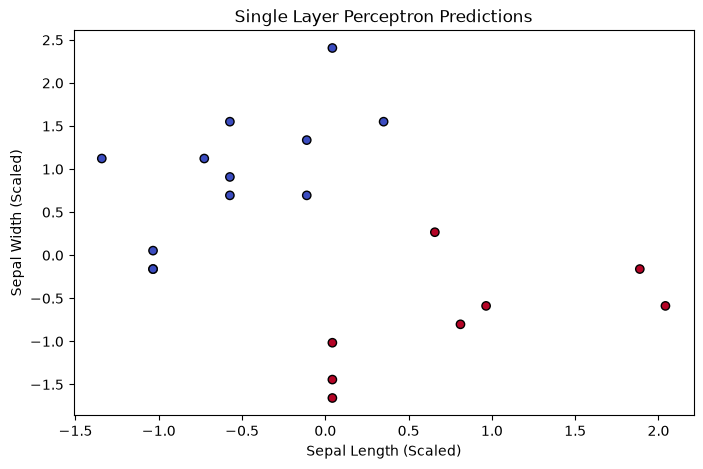

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_pred,
    cmap='coolwarm',
    edgecolors='black'
)

plt.title("Single Layer Perceptron Predictions")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")

plt.show()